In [1]:
!pip install kagglehub --upgrade


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import kagglehub

d:\MLOPS practice\Spam_Classifier_end_to_end\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#download data from kaggle

path=kagglehub.dataset_download("undefinenull/million-song-dataset-spotify-lastfm")
print(path)

C:\Users\HP\.cache\kagglehub\datasets\undefinenull\million-song-dataset-spotify-lastfm\versions\1


In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
#Seperating and saving the datasets
music_data=os.path.join(path,'Music Info.csv')
history_data=os.path.join(path,'User Listening History.csv')

#Reading the datasets
music_df=pd.read_csv(music_data)
history_df=pd.read_csv(history_data)


In [6]:
music_df.head()

,track_id,name,artist,spotify_preview_url,spotify_id,tags,genre,year,duration_ms,danceability,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,TRIOREW128F424EAF0,Mr. Brightside,The Killers,https://p.scdn.co/mp3-preview/4d26180e6961fd46...,09ZQ5TmUG8TSL56n0knqrj,"rock, alternative, indie, alternative_rock, in...",NaN,2004,222200,0.355,...,1,-4.360,1,0.0746,0.001190,0.000000,0.0971,0.240,148.114,4
1,TRRIVDJ128F429B0E8,Wonderwall,Oasis,https://p.scdn.co/mp3-preview/d012e536916c927b...,06UfBBDISthj1ZJAtX4xjj,"rock, alternative, indie, pop, alternative_roc...",NaN,2006,258613,0.409,...,2,-4.373,1,0.0336,0.000807,0.000000,0.2070,0.651,174.426,4
2,TROUVHL128F426C441,Come as You Are,Nirvana,https://p.scdn.co/mp3-preview/a1c11bb1cb231031...,0keNu0t0tqsWtExGM3nT1D,"rock, alternative, alternative_rock, 90s, grunge",RnB,1991,218920,0.508,...,4,-5.783,0,0.0400,0.000175,0.000459,0.0878,0.543,120.012,4
3,TRUEIND128F93038C4,Take Me Out,Franz Ferdinand,https://p.scdn.co/mp3-preview/399c401370438be4...,0ancVQ9wEcHVd0RrGICTE4,"rock, alternative, indie, alternative_rock, in...",NaN,2004,237026,0.279,...,9,-8.851,1,0.0371,0.000389,0.000655,0.1330,0.490,104.560,4
4,TRLNZBD128F935E4D8,Creep,Radiohead,https://p.scdn.co/mp3-preview/e7eb60e9466bc3a2...,01QoK9DA7VTeTSE3MNzp4I,"rock, alternative, indie, alternative_rock, in...",RnB,2008,238640,0.515,...,7,-9.935,1,0.0369,0.010200,0.000141,0.1290,0.104,91.841,4


In [7]:
music_df = music_df.drop(columns=['spotify_preview_url'])

In [8]:
music_df.head()

,track_id,name,artist,spotify_id,tags,genre,year,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,TRIOREW128F424EAF0,Mr. Brightside,The Killers,09ZQ5TmUG8TSL56n0knqrj,"rock, alternative, indie, alternative_rock, in...",NaN,2004,222200,0.355,0.918,1,-4.360,1,0.0746,0.001190,0.000000,0.0971,0.240,148.114,4
1,TRRIVDJ128F429B0E8,Wonderwall,Oasis,06UfBBDISthj1ZJAtX4xjj,"rock, alternative, indie, pop, alternative_roc...",NaN,2006,258613,0.409,0.892,2,-4.373,1,0.0336,0.000807,0.000000,0.2070,0.651,174.426,4
2,TROUVHL128F426C441,Come as You Are,Nirvana,0keNu0t0tqsWtExGM3nT1D,"rock, alternative, alternative_rock, 90s, grunge",RnB,1991,218920,0.508,0.826,4,-5.783,0,0.0400,0.000175,0.000459,0.0878,0.543,120.012,4
3,TRUEIND128F93038C4,Take Me Out,Franz Ferdinand,0ancVQ9wEcHVd0RrGICTE4,"rock, alternative, indie, alternative_rock, in...",NaN,2004,237026,0.279,0.664,9,-8.851,1,0.0371,0.000389,0.000655,0.1330,0.490,104.560,4
4,TRLNZBD128F935E4D8,Creep,Radiohead,01QoK9DA7VTeTSE3MNzp4I,"rock, alternative, indie, alternative_rock, in...",RnB,2008,238640,0.515,0.430,7,-9.935,1,0.0369,0.010200,0.000141,0.1290,0.104,91.841,4


EDA

In [9]:
#shape of music dataset
music_df.shape

(50683, 20)

In [10]:
#Check for null values
music_df.isnull().sum()

track_id                0
name                    0
artist                  0
spotify_id              0
tags                 1127
genre               28335
year                    0
duration_ms             0
danceability            0
energy                  0
key                     0
loudness                0
mode                    0
speechiness             0
acousticness            0
instrumentalness        0
liveness                0
valence                 0
tempo                   0
time_signature          0
dtype: int64

In [11]:
%pip install missingno matplotlib pandas

  Using cached missingno-0.5.2-py3-none-any.whl.metadata (639 bytes)
Using cached missingno-0.5.2-py3-none-any.whl (8.7 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


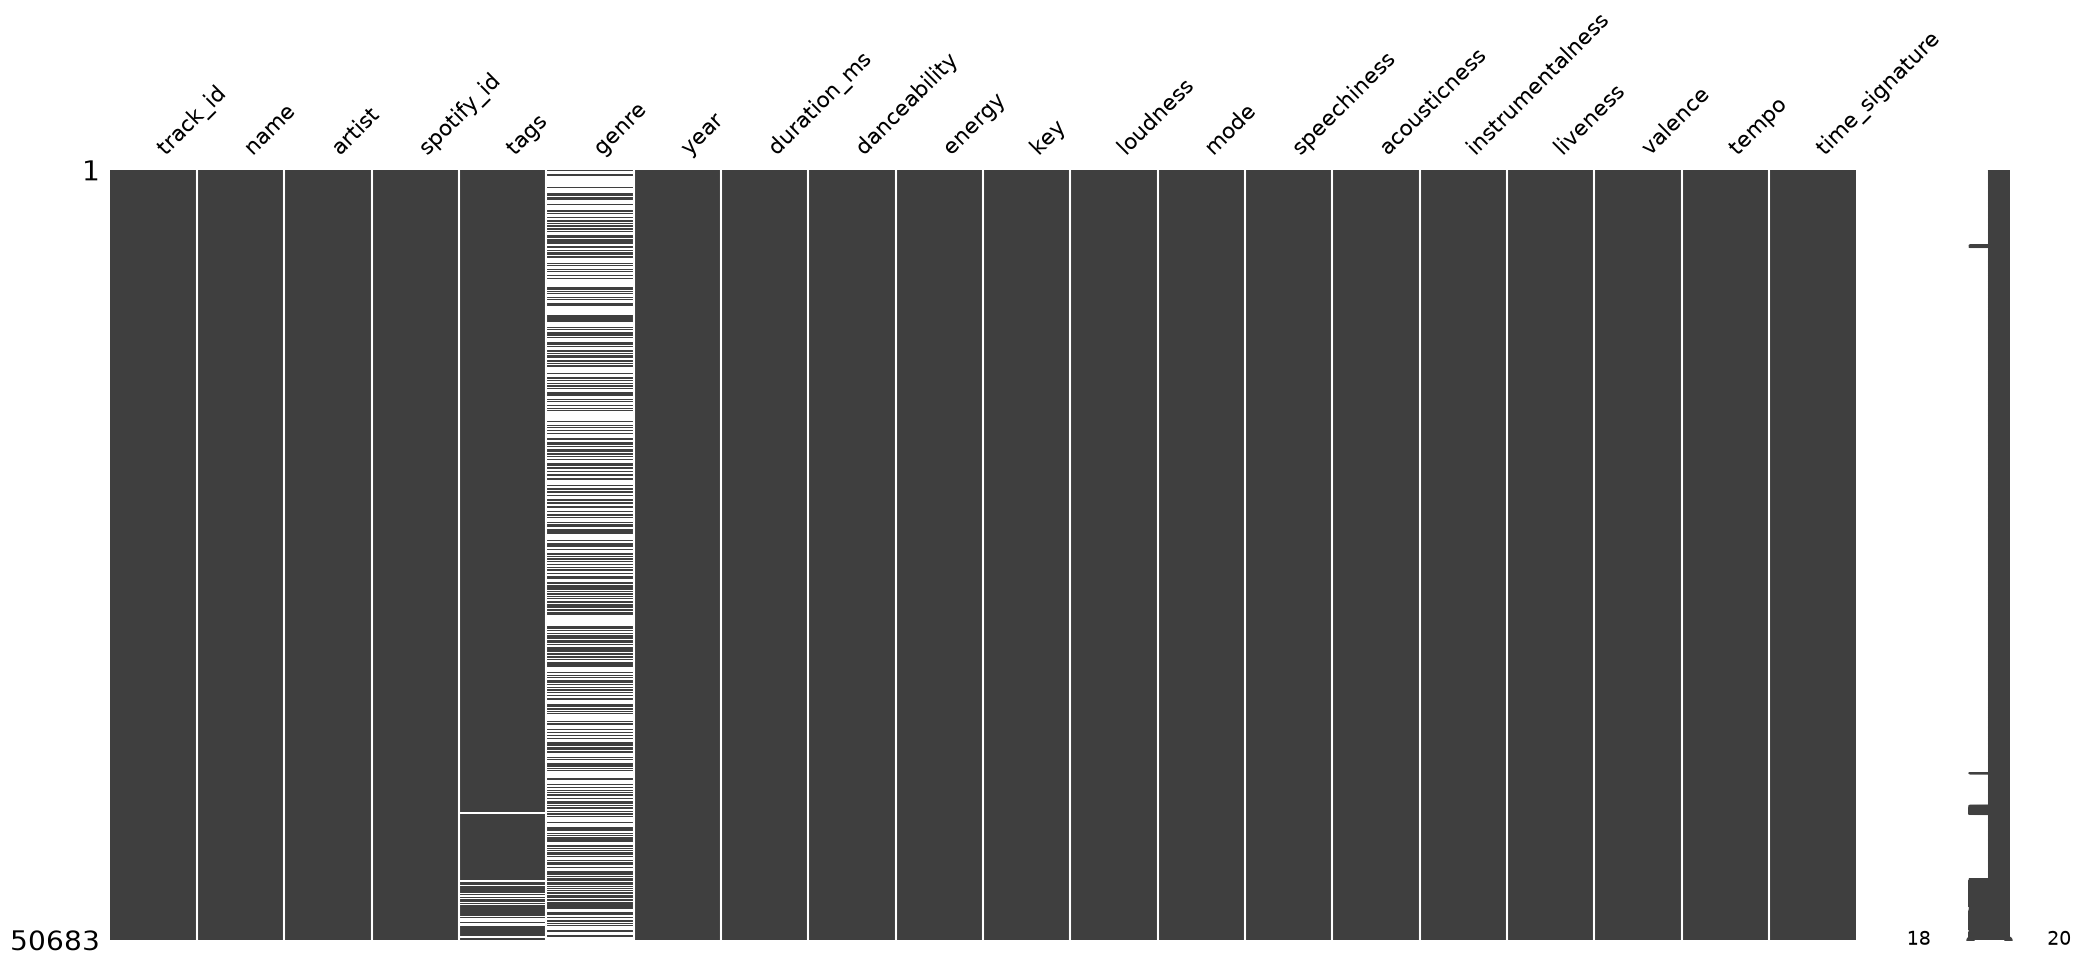

In [12]:
import missingno as msno
msno.matrix(music_df)
plt.show()


In [13]:
#ratio of missing data
music_df.isna().mean().sort_values(ascending=False).head(2).mul(100)

genre    55.906320
tags      2.223625
dtype: float64

Duplicate rows

In [14]:
#duplicates in the data
music_df.assign(name=music_df['name'].str.lower()).duplicated(subset=('name')).sum()

np.int64(815)

In [15]:
#check for duplicates in rows
music_df.loc[
    music_df.assign(name=music_df['name'].str.lower())
    .duplicated(subset=('name'), keep=False)
].assign(
    name=music_df['name'].str.lower()
).sort_values('name')

,track_id,name,artist,spotify_id,tags,genre,year,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
34480,TRKKZMK128F4257579,3 am,Liv Kristine,1TgsnkiolcBhQssCR37JXx,"female_vocalists, power_metal, gothic_metal, g...",NaN,2005,302880,0.516,0.840,0,-6.038,0,0.0390,0.152000,0.005970,0.107,0.441,78.009,4
6588,TRGGALK12903CB68E5,3 am,Matchbox Twenty,5vYA1mW9g2Coh1HUFUSmlb,"rock, alternative, pop, alternative_rock, 90s,...",NaN,1996,225946,0.521,0.673,8,-8.685,1,0.0284,0.005730,0.000000,0.120,0.543,108.031,4
29795,TRLOXMF128F934BF04,3am,Matchbox Twenty,5vYA1mW9g2Coh1HUFUSmlb,"rock, alternative, 90s, piano, american, pop_rock",NaN,1996,225946,0.521,0.673,8,-8.685,1,0.0284,0.005730,0.000000,0.120,0.543,108.031,4
43800,TRPWOAS128E0781045,3am,Halsey,1OfLNb6dQ9dra1B58iT9Ex,pop_rock,NaN,2020,234858,0.385,0.871,0,-4.604,0,0.0795,0.009060,0.000000,0.579,0.538,189.760,4
15088,TRJRBRX128F4255789,4th of july,Soundgarden,237oH9rNUYpIBeHfAn3WJ0,"hard_rock, 90s, grunge",NaN,1994,308866,0.368,0.749,5,-5.523,0,0.0392,0.109000,0.000372,0.175,0.193,141.901,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34772,TRJFGYO128F4259743,you're the one that i want,Lo-Fang,1dEHQktvcM8vCCyI1x7yVB,"indie, male_vocalists, cover",NaN,2014,204706,0.445,0.309,11,-12.517,0,0.0404,0.643000,0.000369,0.224,0.153,119.754,4
32677,TRFZYLL128F146902A,you've really got a hold on me,Smokey Robinson and The Miracles,03AkIZeRvGpTvDF9vNJtdj,"soul, 60s, oldies",Rock,2012,179513,0.674,0.515,0,-6.895,1,0.0296,0.724000,0.000000,0.339,0.596,116.678,3
20976,TRUXHGS128F145E41A,you've really got a hold on me,The Miracles,01FtGX94CSvO5Zxs5B6AMM,"soul, 60s, oldies",NaN,1994,180266,0.679,0.406,0,-10.533,1,0.0312,0.755000,0.000000,0.412,0.511,117.940,3
27680,TRXWPMW12903CB42A0,zombies,Childish Gambino,73kAUSAht4YOR7xNPmNb2L,funk,NaN,2016,281813,0.653,0.411,0,-11.986,1,0.1270,0.503000,0.000969,0.067,0.468,160.055,4


In [16]:
#duplicates on the basis for spotify_id
music_df.duplicated(subset='spotify_id').sum()

np.int64(9)

In [17]:
music_df.duplicated(subset=['spotify_id','year','duration_ms']).sum()

np.int64(9)

In [18]:
music_df.drop_duplicates(subset=['spotify_id','year','duration_ms'],inplace=True)

In [19]:
music_df.duplicated(subset=['spotify_id','year','duration_ms']).sum()

np.int64(0)

##Columwise Analysis

In [20]:
categorical_cols=music_df.select_dtypes(include="object").columns
categorical_cols

C:\Users\HP\AppData\Local\Temp\ipykernel_16172\2191466346.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols=music_df.select_dtypes(include="object").columns


Index(['track_id', 'name', 'artist', 'spotify_id', 'tags', 'genre'], dtype='str')

In [21]:
def categorical_analysis(df,feature_names,k_artist=20):
  for feature in feature_names:
    print(f"Number of categories in columns {feature} are ",df[feature].str.lower().nunique())
    if feature in ["artist","genre"]:
      print(df[feature].value_counts().head(k_artist))

    if feature == "genre":
      print(f"The unique categories in {feature} column are: ",df[feature].dropna().unique())

    print('--'*100)

In [22]:
categorical_analysis(music_df,categorical_cols)

Number of categories in columns track_id are  50674
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Number of categories in columns name are  49860
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Number of categories in columns artist are  8317
artist
The Rolling Stones    132
Radiohead             110
Autechre              105
Tom Waits             100
Bob Dylan              98
The Cure               94
Metallica              85
Johnny Cash            84
Nine Inch Nails        83
Sonic Youth            81
Iron Maiden            76
Elliott Smith          76
In Flames              76
Boards of Canada       75
Mogwai                 75
Amorphis               74
Korn                   72


###Observation
1)The track id and spotify id is unique for every row.

2)Some song name are same this is because the song is same but sung by different artist.

3)The dataset contains 8317 songs.

4)There are 15 distinct categories in genre columns.

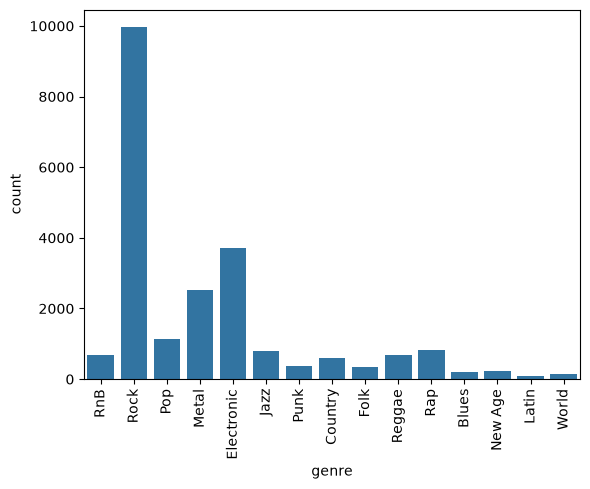

In [23]:
sns.countplot(music_df,x='genre')
plt.xticks(rotation=90)
plt.show()


In [24]:
genre_group=music_df.groupby("genre")
genre_group[['genre','tags']].sample(3)

,genre,tags
26189,Blues,"post_rock, country, cover"
38731,Blues,"blues, guitar, blues_rock"
44341,Blues,"rock, 70s, blues_rock"
23875,Country,"female_vocalists, blues, country, cover, mellow"
11770,Country,"ambient, instrumental, chillout, trance, new_age"
16869,Country,"singer_songwriter, country, love"
11220,Electronic,"electronic, ambient, house, techno, electro"
17295,Electronic,"electronic, dance, house, electro"
36850,Electronic,"electronic, electro, french"
12169,Folk,"indie, experimental, folk, american, 00s"


In [25]:
# song titles in the data that are not in english
(   music_df
    .loc[
        music_df
        .loc[:,"name"]
        .str.contains("[^\d\w\s.?!':;-_(){},\.#-&/-]")
    ]
)

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
C:\Users\HP\AppData\Local\Temp\ipykernel_16172\1748745484.py:6: SyntaxWarning: invalid escape sequence '\d'
  .str.contains("[^\d\w\s.?!':;-_(){},\.#-&/-]")


,track_id,name,artist,spotify_id,tags,genre,year,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
2455,TRBGIZH128F4252D9E,2 + 2 = 5,Radiohead,0dUSgj5UiJHY92RCuEFYcx,"rock, electronic, alternative, indie, alternat...",Rock,2008,199360,0.443,0.717,5,-5.498,0,0.0504,0.182000,0.000051,0.3450,0.3860,149.582,4
4463,TRGHMRU128F1478067,"I Put The ""Metro"" In Metronome",Cute Is What We Aim For,718VxOgHaLU7oGS9686hg6,"alternative, emo",Rock,2006,206053,0.538,0.858,11,-3.862,1,0.0638,0.085200,0.000000,0.2580,0.7060,149.971,4
6870,TRGIILN12903CE46BB,1+1,Beyoncé,0b4bcwV5QWTzgza5u1gh5C,"female_vocalists, soul, rnb, beautiful",NaN,2011,273880,0.303,0.384,6,-7.342,1,0.0339,0.381000,0.000005,0.0661,0.2610,63.345,5
7902,TRZMLSV128F9305C8C,B********,Rammstein,2fKyVXrtvFkqv5lVPf1UXa,"metal, industrial, german",Rock,2009,254013,0.352,0.905,9,-3.792,1,0.0836,0.000895,0.218000,0.1810,0.3270,141.016,3
7974,TRFRAEO128F4279C87,F**k the System,System of a Down,0uvPnGOwcaUNT6gwJF98wL,"metal, nu_metal",Metal,2002,132733,0.474,0.994,8,-1.884,1,0.1030,0.002160,0.126000,0.3140,0.8470,171.433,4
10722,TRODWHD128F92FD8BA,4 + 20,"Crosby, Stills, Nash & Young",2jZPEeW2ynykb2GkVqpOkJ,"rock, classic_rock, folk, singer_songwriter, a...",Rock,1970,126640,0.638,0.058,4,-25.243,1,0.0388,0.928000,0.079000,0.1130,0.1260,140.964,4
13127,TRLMIXB128EF3435DD,M+M's,blink-182,0z6VQdAqi0HjQYULMUYpBt,"punk, punk_rock",NaN,2005,155680,0.212,0.921,9,-6.092,1,0.0567,0.000054,0.003990,0.0669,0.6800,159.629,4
14454,TRKEIVB128F930A597,"Nuthin' But a ""G"" Thang",Dr. Dre,1qaZx6y94LiMy2KdhHxRTy,"rap, 90s, hip_hop",NaN,2005,230026,0.817,0.704,7,-8.336,1,0.2850,0.009390,0.000000,0.0850,0.6800,94.627,4
17862,TRBZLOG12903CB78FD,I Belong To You [+Mon Coeur S'Ouvre A Ta Voix],Muse,114rzL6VEy9bb3amPcY3tw,"rock, alternative_rock, progressive_rock, soun...",Rock,2009,338813,0.481,0.603,2,-6.590,1,0.0280,0.166000,0.032100,0.1090,0.2130,105.974,4
22541,TRYVOPZ128F4254176,£4,These New Puritans,1LsQ5WkLU8ubiAz6AtMNll,"electronic, alternative, british, industrial, ...",Rock,2008,133173,0.692,0.759,11,-9.216,1,0.0533,0.052200,0.012900,0.4630,0.2560,99.988,4


In [26]:
all_tags=[]
for tags in music_df['tags'].dropna().str.replace(' ','').str.split(","):
  all_tags.extend(tags)


In [27]:

print("The number of unique tags are ",len(set(all_tags)))

The number of unique tags are  100


In [28]:
set(all_tags)

{'00s',
 '60s',
 '70s',
 '80s',
 '90s',
 'acoustic',
 'alternative',
 'alternative_rock',
 'ambient',
 'american',
 'avant_garde',
 'beautiful',
 'black_metal',
 'blues',
 'blues_rock',
 'british',
 'britpop',
 'chill',
 'chillout',
 'classic_rock',
 'classical',
 'country',
 'cover',
 'dance',
 'dark_ambient',
 'death_metal',
 'doom_metal',
 'downtempo',
 'drum_and_bass',
 'electro',
 'electronic',
 'emo',
 'experimental',
 'female_vocalists',
 'folk',
 'french',
 'funk',
 'german',
 'gothic',
 'gothic_metal',
 'grindcore',
 'grunge',
 'guitar',
 'hard_rock',
 'hardcore',
 'heavy_metal',
 'hip_hop',
 'house',
 'idm',
 'indie',
 'indie_pop',
 'indie_rock',
 'industrial',
 'instrumental',
 'j_pop',
 'japanese',
 'jazz',
 'lounge',
 'love',
 'male_vocalists',
 'mellow',
 'melodic_death_metal',
 'metal',
 'metalcore',
 'new_age',
 'new_wave',
 'noise',
 'nu_metal',
 'oldies',
 'piano',
 'polish',
 'pop',
 'pop_rock',
 'post_hardcore',
 'post_punk',
 'post_rock',
 'power_metal',
 'progress

##Integer based Columns
####Key

What it means: The musical key in which the song is composed, represented as integers (e.g., 0 = C, 1 = C#, 2 = D, etc., up to 11).

->When value is small: Represents keys like C or D, often associated with simplicity or familiarity.

->When value is large: Represents keys like A# or B, which may sound brighter or more complex, depending on the context.

###Mode

What it means: Refers to the modality of the song, where 0 = minor (often associated with sadness or tension) and 1 = major (associated with happiness or resolution).

->When value is small: Indicates the song is in a minor mode, creating a more somber or serious tone.

->When value is large: Indicates the song is in a major mode, giving it a cheerful and uplifting feel.

###Time Signature

What it means: The number of beats in each bar of music, typically expressed as an integer (e.g., 4 for 4/4 time).

->When value is small: Indicates fewer beats per measure (e.g., 3), which can create a waltz-like or less conventional rhythm.

->When value is large: Indicates more beats per measure (e.g., 5 or 7), often leading to a more complex or experimental rhythmic structure.

->A value of 4 in the time signature typically means the song is in 4/4 time, also known as "common time." This means there are 4 beats per measure, and the quarter note gets one beat.


Impact of a 4 Time Signature:

->Musical Feel: It creates a steady, balanced, and natural rhythm that is easy to follow.

->Prevalence: It is the most common time signature in Western music, used in many genres like pop, rock, classical, and jazz.

->Examples: Songs like "Billie Jean" by Michael Jackson or "Shape of You" by Ed Sheeran are in 4/4.

In [29]:
integer_columns = music_df.select_dtypes(include="int").columns
integer_columns

Index(['year', 'duration_ms', 'key', 'mode', 'time_signature'], dtype='str')

In [30]:
#statical summary
(
    music_df
    .loc[:,integer_columns]
    .drop(columns=["duration_ms"])
    .assign(**{
        col: music_df[col].astype("object")
        for col in integer_columns.drop("duration_ms")
    })
    .describe()
)

,year,key,mode,time_signature
count,50674,50674,50674,50674
unique,75,12,2,5
top,2007,9,1,4
freq,4221,5907,31979,44981


In [31]:

# range of data

(
    music_df
    .loc[:,integer_columns]
    .assign(duration_minutes=music_df["duration_ms"].div(1000).div(60))
    .drop(columns=["duration_ms"])
    .agg(["min","max"])
)

,year,key,mode,time_signature,duration_minutes
min,1900,0,0,0,0.023983
max,2022,11,1,5,63.606217


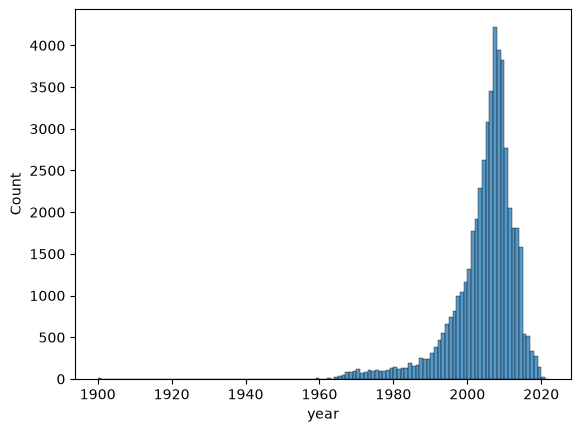

In [32]:

# number of songs per year in data

sns.histplot(music_df,x="year",bins=music_df["year"].max() - music_df["year"].min(),stat="count")
plt.show()

In [33]:
#most songs by year
music_df.loc[:,"year"].value_counts().head(5).sort_index()

year
2005    3085
2006    3453
2007    4221
2008    3947
2009    3827
Name: count, dtype: int64

In [34]:
# unique values in the key column
(
    np.sort(music_df
            .loc[:,"key"]
            .unique())
)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

<Axes: title={'center': 'Percentage of Songs wrt to Key'}, xlabel='Percentage', ylabel='key'>

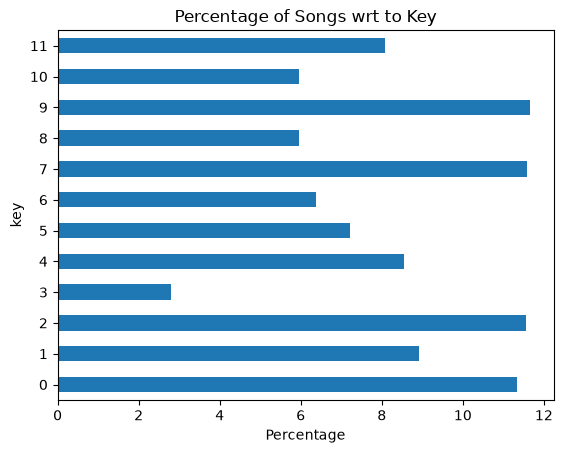

In [35]:

# percentage of songs wrt to key in the data

(
    music_df['key']
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
    .plot(kind='barh',title="Percentage of Songs wrt to Key",xlabel="Percentage")
)

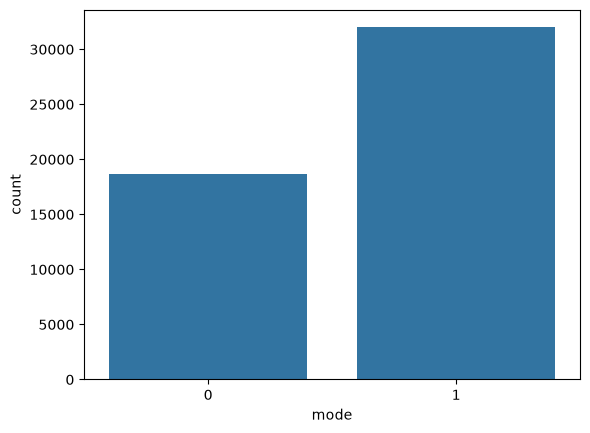

In [36]:
# countplot for mode

sns.countplot(music_df,x="mode")
plt.show()

In [37]:
#unique value in time signature
np.sort(music_df.loc[:,"time_signature"].unique())

array([0, 1, 3, 4, 5])

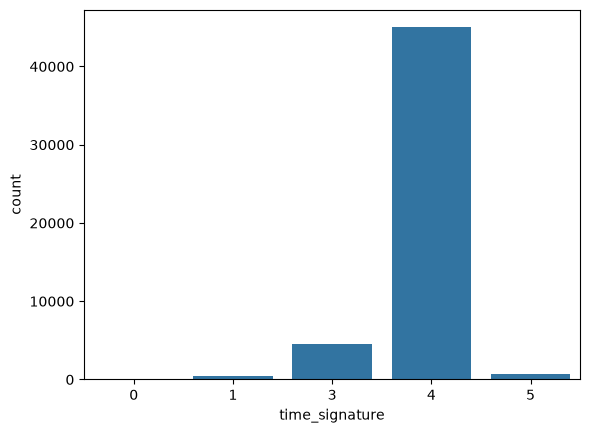

In [38]:
sns.countplot(music_df,x="time_signature")
plt.show()

In [39]:
music_df['time_signature'].value_counts(normalize=True).mul(100)

time_signature
4    88.765442
3     8.880294
5     1.444528
1     0.890003
0     0.019734
Name: proportion, dtype: float64

In [40]:

# statistical summary of time duration

(
    music_df
    .loc[:,["duration_ms"]]
    .assign(duration_minutes=music_df["duration_ms"].div(1000).div(60))
    .drop(columns="duration_ms")
    .describe()
)

,duration_minutes
count,50674.000000
mean,4.185893
std,1.793154
min,0.023983
25%,3.212217
50%,3.915550
75%,4.803046
max,63.606217


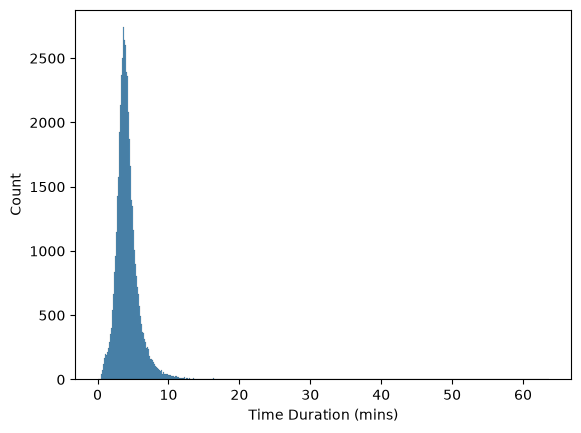

In [41]:
time_duration_mins=music_df["duration_ms"].div(1000).div(60)

sns.histplot(time_duration_mins)
plt.xlabel("Time Duration (mins)")
plt.show()

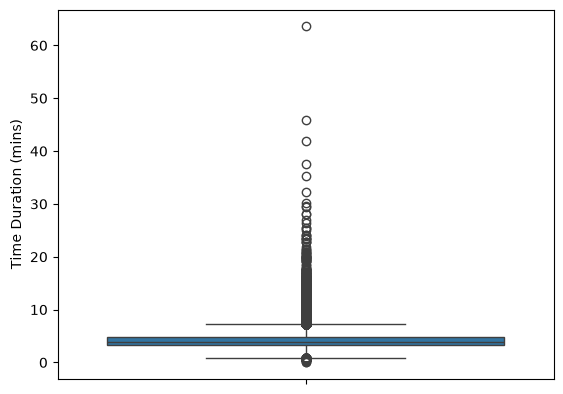

In [42]:

# time duration boxplot

sns.boxplot(time_duration_mins)
plt.ylabel("Time Duration (mins)")
plt.show()

In [43]:

# song that is longer than 60 mins

(
    music_df
    .loc[time_duration_mins > 60]
)

,track_id,name,artist,spotify_id,tags,genre,year,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
25337,TRDAOJL128F932C383,Dopesmoker,Sleep,1vhvheW4R0KbK6Kr3NFplW,"psychedelic, doom_metal",NaN,2003,3816373,0.16,0.572,5,-6.949,1,0.0321,0.00367,0.745,0.0952,0.0932,96.926,4


###Continous Columns

In [44]:
continous_cols=music_df.select_dtypes(include='float').columns
continous_cols

Index(['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo'],
      dtype='str')

####Danceability:

What it means: Measures how suitable a track is for dancing, based on tempo, rhythm stability, beat strength, and overall regularity.

When value is small: The song may feel less rhythmic or harder to dance to, like ballads or experimental music.

When value is large: The song is highly danceable, with a strong beat and rhythmic consistency, ideal for clubs or parties.

####Energy:

What it means: Represents the intensity and activity of a song, considering factors like loudness, tempo, and instrumentation.

When value is small: The song feels mellow, calm, or laid-back, such as acoustic or chill tracks.

When value is large: The song feels loud, energetic, and lively, often found in rock or EDM genres.

####Loudness:

What it means: The overall volume of the song in decibels (dB), averaged over the track.

When value is small: The song is quieter, suitable for soft or ambient styles.

When value is large: The song is louder and more powerful, typically associated with dynamic or energetic tracks.

####Speechiness:

What it means: Measures the presence of spoken words in a track. A higher value indicates more speech-like content.

When value is small: The song is more musical, with fewer spoken or rap-like elements.

When value is large: The track has spoken word, podcast-style content, or heavy rap influence.

####Acousticness:

What it means: Reflects how acoustic (non-electronic) the track is.

When value is small: The track is more electronic or synthetic in nature.

When value is large: The track is acoustic, featuring instruments like guitar, piano, or strings.

####Instrumentalness:

What it means: Predicts the likelihood of a song having no vocals (purely instrumental).

When value is small: The track likely has vocals or lyrics.

When value is large: The track is primarily instrumental, like classical or ambient music.

####Liveness:

What it means: Measures the presence of a live audience in the recording.

When value is small: The track sounds studio-produced without live ambiance.

When value is large: The track feels live, with audience sounds or a concert vibe.

####Valence:

What it means: Indicates the positivity or happiness of a track's mood.

When value is small: The song feels sad, somber, or emotionally heavy.

When value is large: The song feels cheerful, uplifting, or happy.

####Tempo:

What it means: The speed of the song in beats per minute (BPM).

When value is small: The song is slow-paced, such as ballads or downtempo tracks.

When value is large: The song is fast-paced, like dance or upbeat genres.

In [45]:

def numerical_analysis(df,columns):
    for column in columns:
        print(f"Numerical Analysis for column {column}")
        print("Statistical Summary")
        print(df[column].describe())

        fig = plt.figure(figsize=(12,4))
        # hitogram for column
        plt.subplot(1,2,1)
        sns.histplot(df[column])
        plt.title(f"Histogram for {column}")
        # boxplot for column
        plt.subplot(1,2,2)
        sns.boxplot(df[column])
        plt.title(f"Boxplot for {column}")
        plt.show()

        print("--" * 120)
    print("*" * 120)
    print("Pairplot")
    sns.pairplot(df[columns])
    plt.show()

Numerical Analysis for column danceability
Statistical Summary
count    50674.000000
mean         0.493522
std          0.178833
min          0.000000
25%          0.364000
50%          0.497000
75%          0.621000
max          0.986000
Name: danceability, dtype: float64


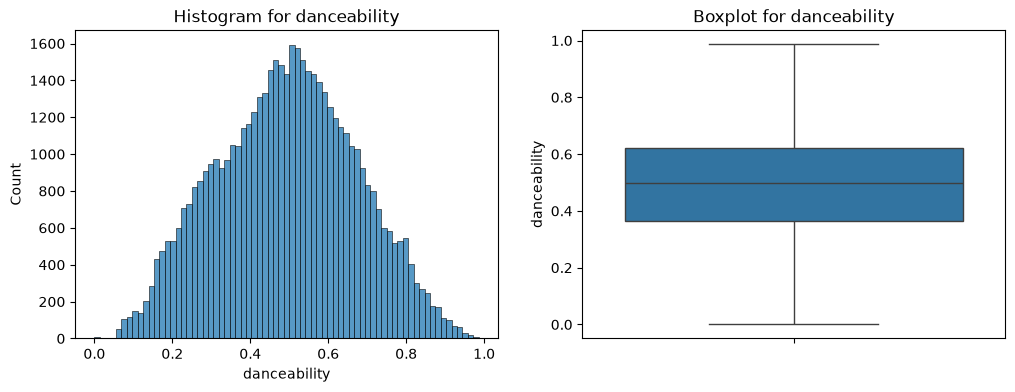

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column energy
Statistical Summary
count    50674.000000
mean         0.686507
std          0.251803
min          0.000000
25%          0.514000
50%          0.744000
75%          0.905000
max          1.000000
Name: energy, dtype: float64


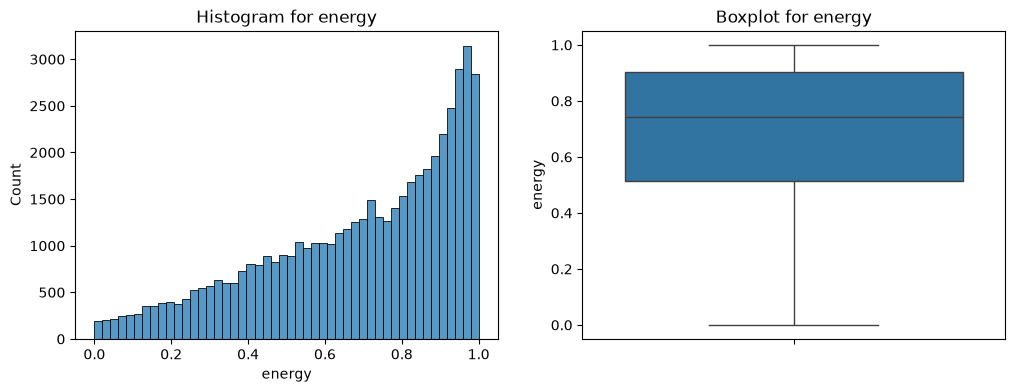

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column loudness
Statistical Summary
count    50674.000000
mean        -8.291007
std          4.548359
min        -60.000000
25%        -10.375000
50%         -7.199500
75%         -5.089000
max          3.642000
Name: loudness, dtype: float64


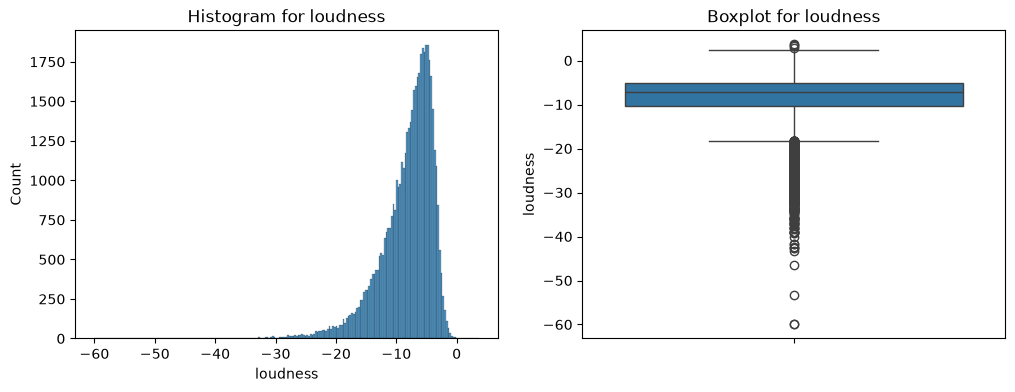

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column speechiness
Statistical Summary
count    50674.000000
mean         0.076026
std          0.076012
min          0.000000
25%          0.035200
50%          0.048200
75%          0.083500
max          0.954000
Name: speechiness, dtype: float64


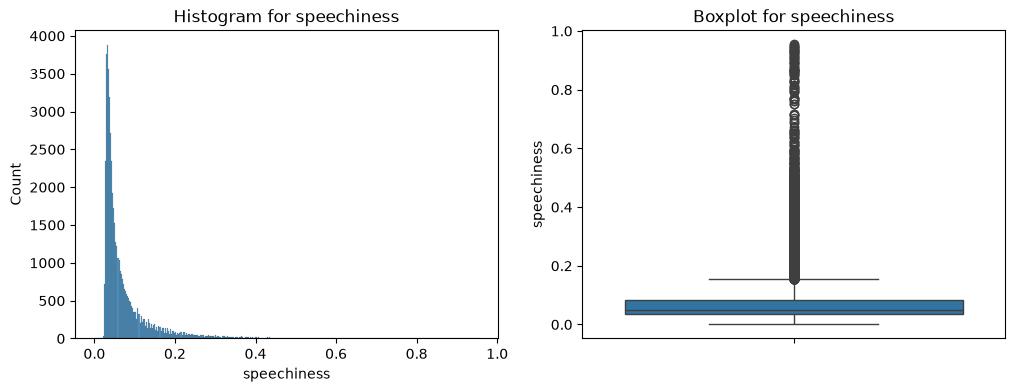

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column acousticness
Statistical Summary
count    50674.000000
mean         0.213798
std          0.302839
min          0.000000
25%          0.001400
50%          0.039900
75%          0.340000
max          0.996000
Name: acousticness, dtype: float64


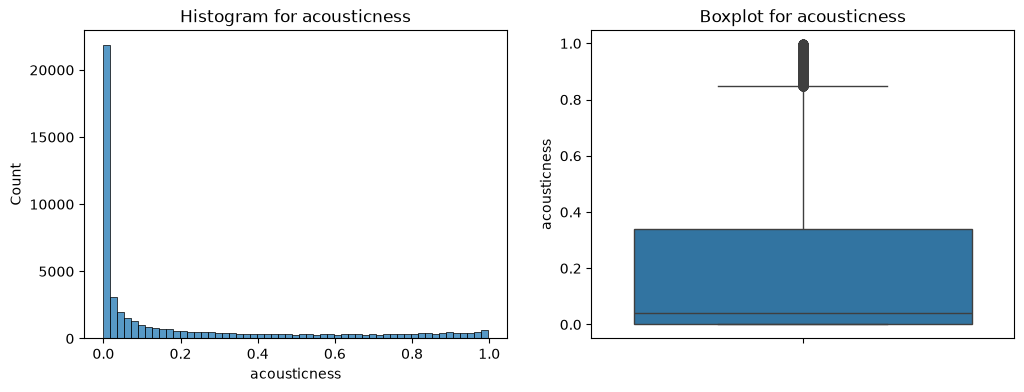

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column instrumentalness
Statistical Summary
count    50674.000000
mean         0.225299
std          0.337067
min          0.000000
25%          0.000018
50%          0.005630
75%          0.441000
max          0.999000
Name: instrumentalness, dtype: float64


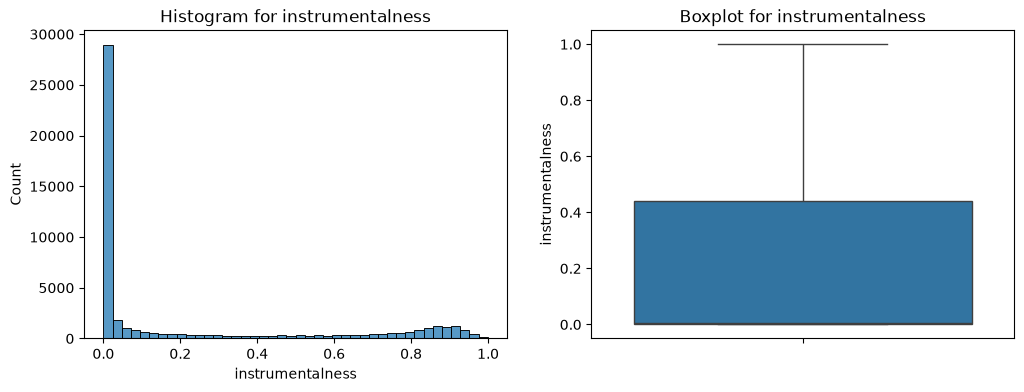

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column liveness
Statistical Summary
count    50674.000000
mean         0.215439
std          0.184708
min          0.000000
25%          0.098400
50%          0.138000
75%          0.289000
max          0.999000
Name: liveness, dtype: float64


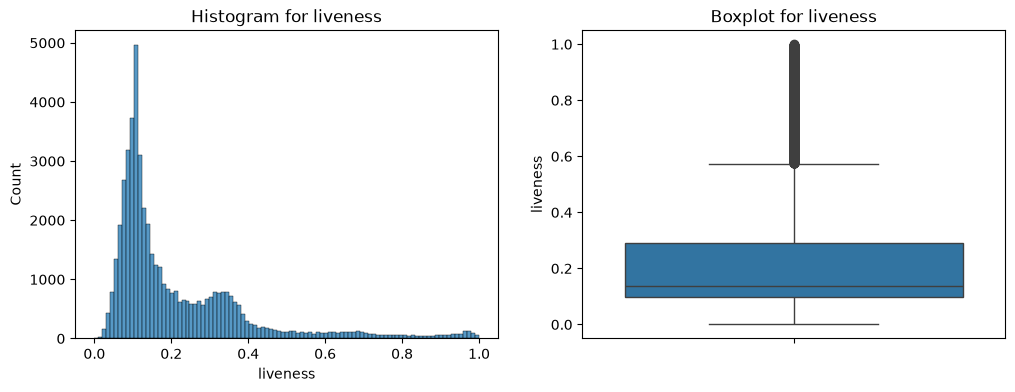

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column valence
Statistical Summary
count    50674.000000
mean         0.433113
std          0.258767
min          0.000000
25%          0.214000
50%          0.405000
75%          0.634000
max          0.993000
Name: valence, dtype: float64


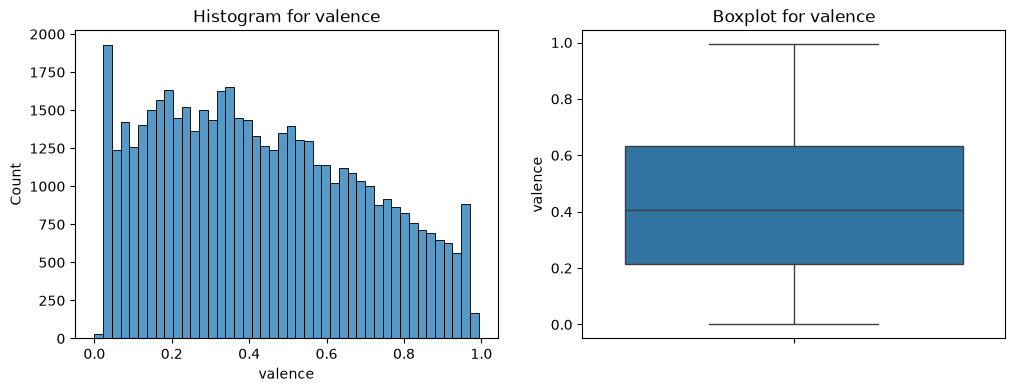

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numerical Analysis for column tempo
Statistical Summary
count    50674.000000
mean       123.508794
std         29.622349
min          0.000000
25%        100.682500
50%        121.989000
75%        141.642250
max        238.895000
Name: tempo, dtype: float64


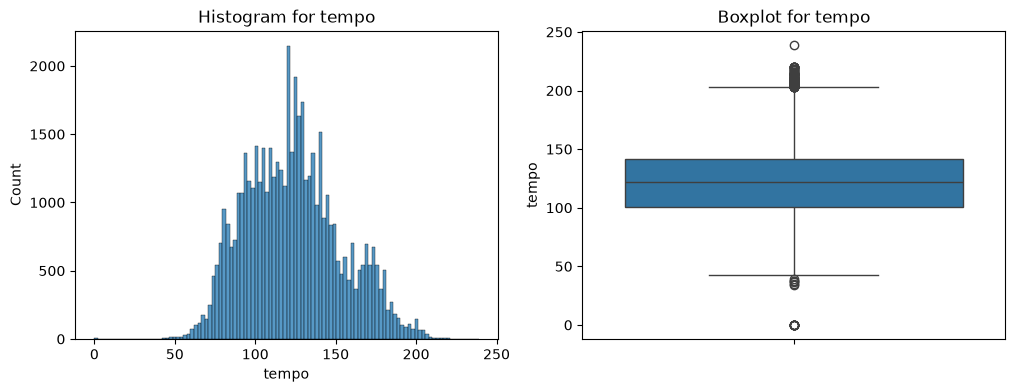

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
************************************************************************************************************************
Pairplot


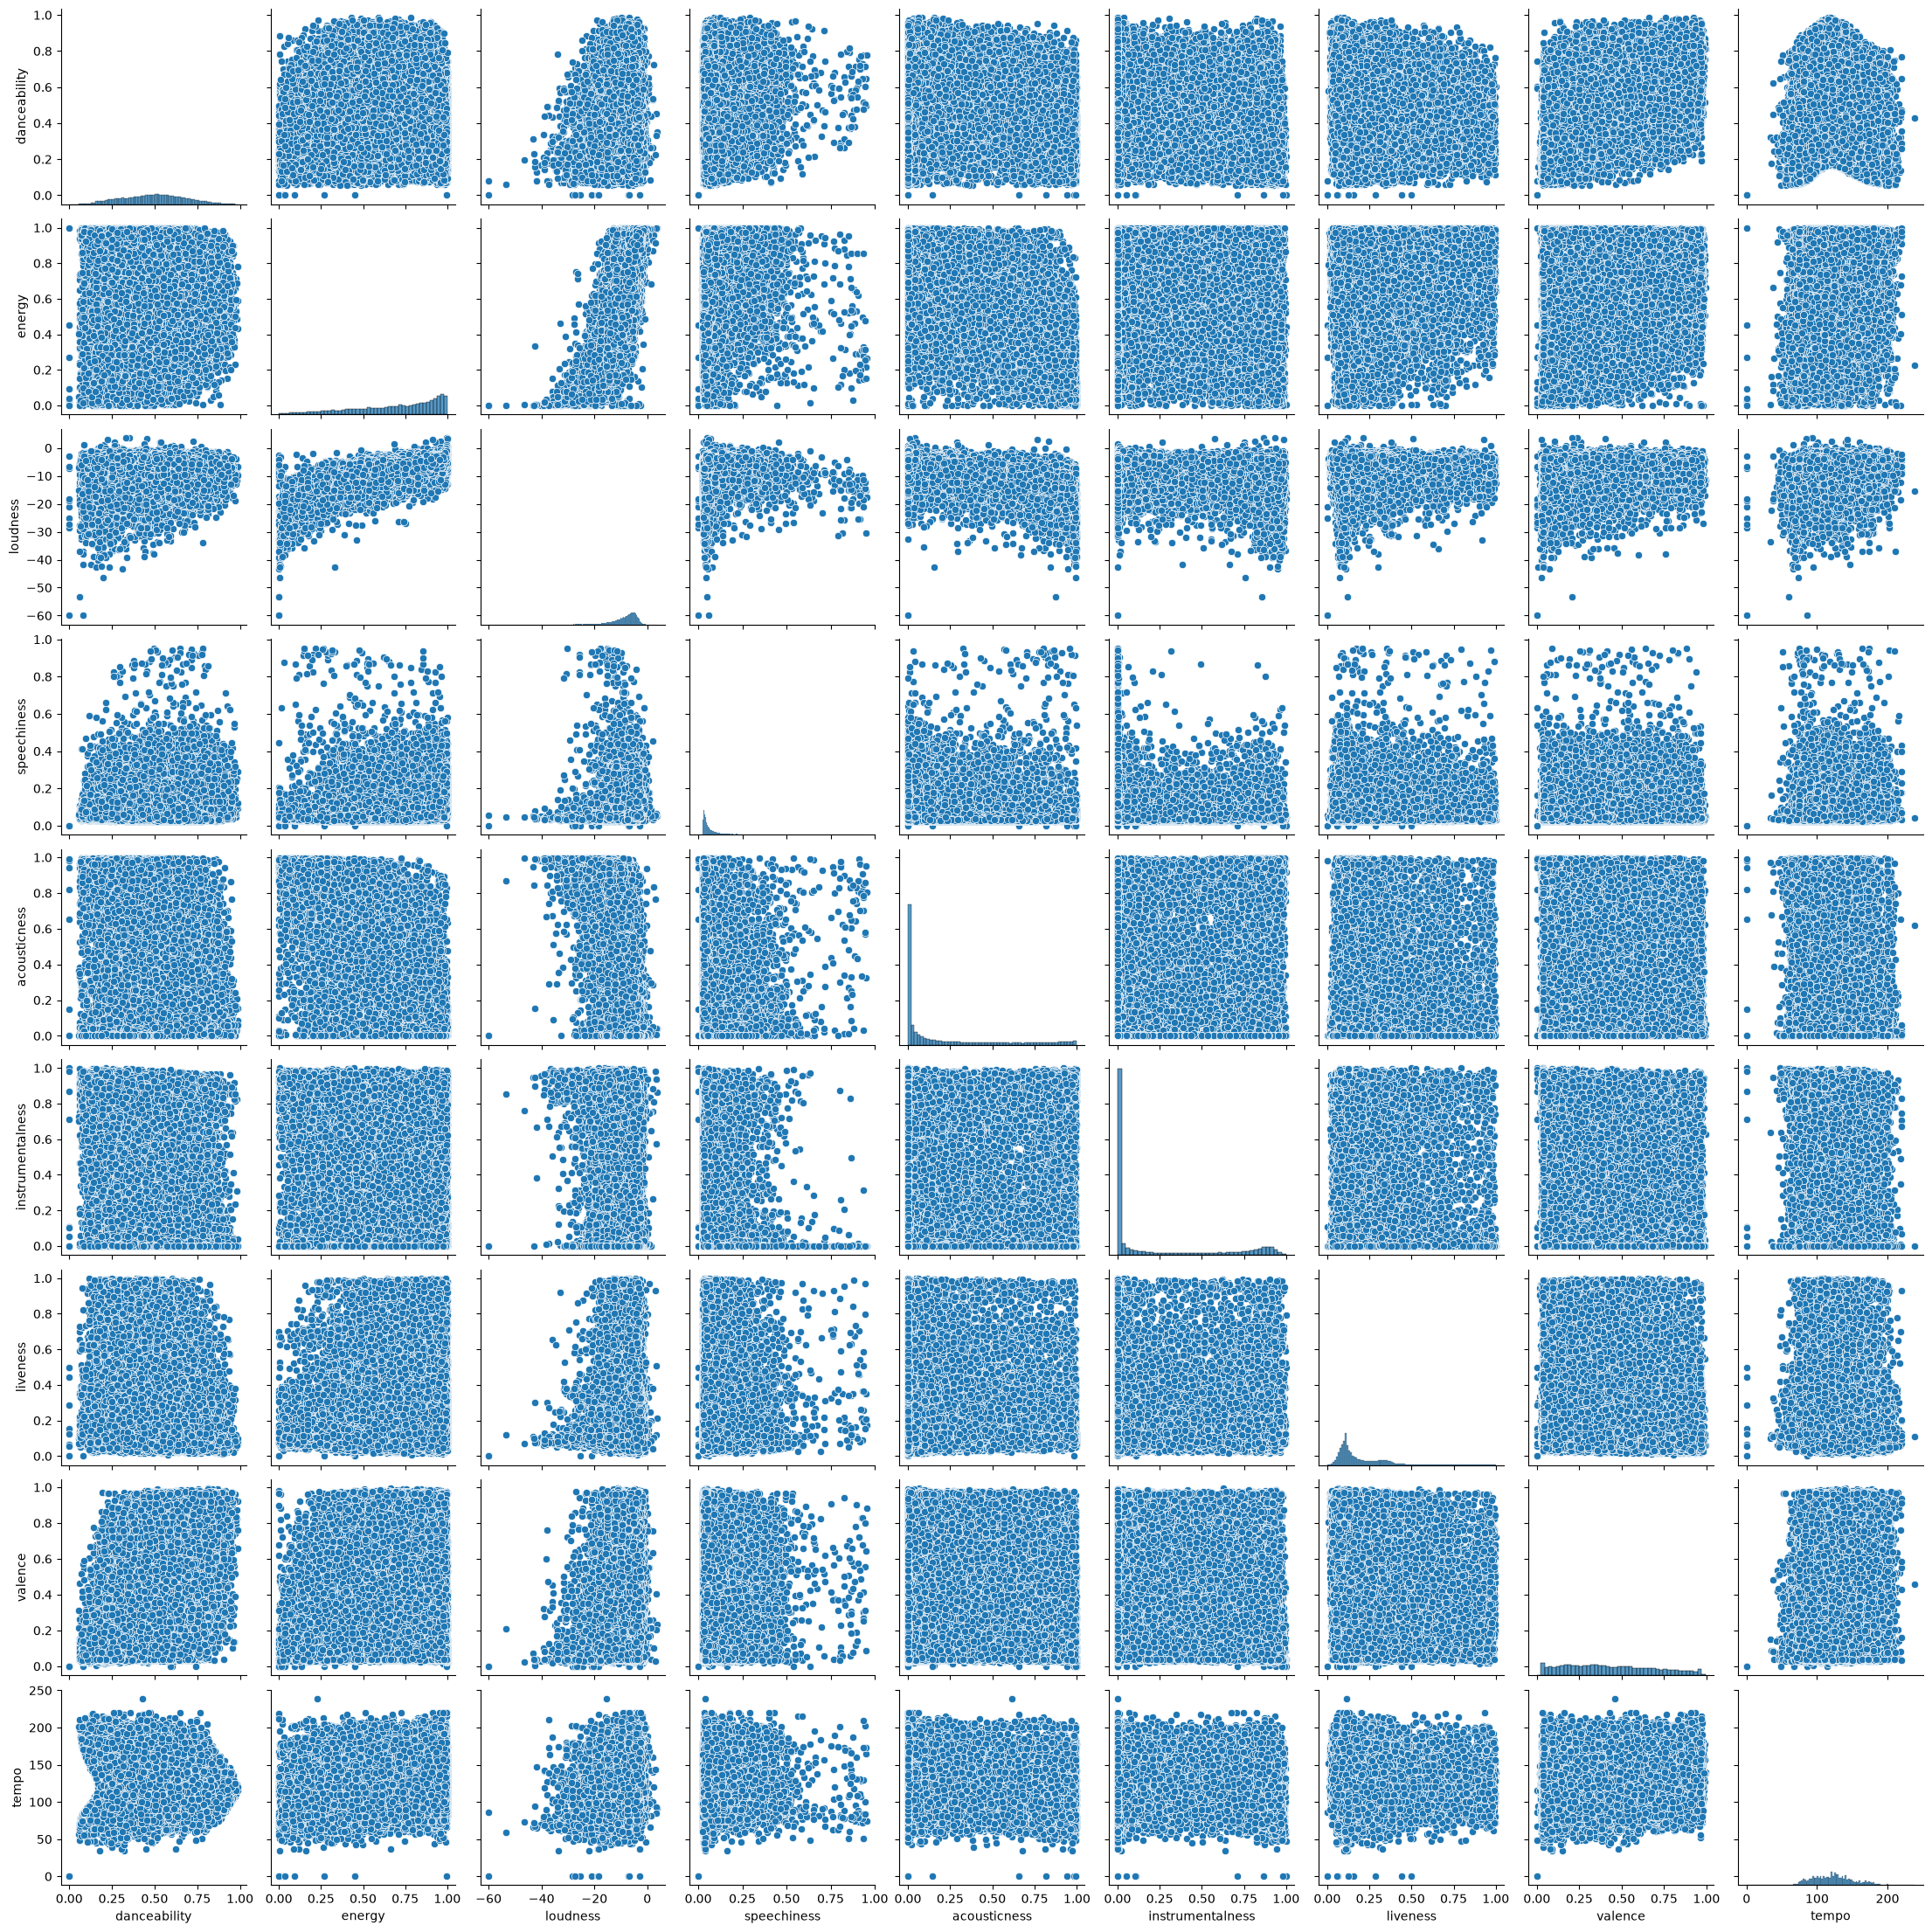

In [46]:
numerical_analysis(music_df,continous_cols)

EDA for USER AND SONG DATA

In [47]:
history_df

,track_id,user_id,playcount
0,TRIRLYL128F42539D1,b80344d063b5ccb3212f76538f3d9e43d87dca9e,1
1,TRFUPBA128F934F7E1,b80344d063b5ccb3212f76538f3d9e43d87dca9e,1
2,TRLQPQJ128F42AA94F,b80344d063b5ccb3212f76538f3d9e43d87dca9e,1
3,TRTUCUY128F92E1D24,b80344d063b5ccb3212f76538f3d9e43d87dca9e,1
4,TRHDDQG12903CB53EE,b80344d063b5ccb3212f76538f3d9e43d87dca9e,1
...,...,...,...
9711296,TRBKFKL128E078ED76,b7815dbb206eb2831ce0fe040d0aa537e2e800f7,1
9711297,TRYFXPG128E078ECBD,b7815dbb206eb2831ce0fe040d0aa537e2e800f7,1
9711298,TROBUUZ128F4263002,b7815dbb206eb2831ce0fe040d0aa537e2e800f7,1
9711299,TROEWXC128F148C83E,b7815dbb206eb2831ce0fe040d0aa537e2e800f7,1


In [48]:
history_df.shape

(9711301, 3)

In [49]:
history_df.duplicated().sum()

np.int64(0)

In [50]:
history_df.isnull().sum()

track_id     0
user_id      0
playcount    0
dtype: int64

In [51]:
history_df['user_id'].nunique()

962037

In [52]:
history_df['track_id'].nunique()

30459

In [53]:
top_10_songs=history_df['track_id'].value_counts().head(10)
top_10_songs

track_id
TRONYHY128F92C9D11    80656
TRUFTBY128F93450B8    39529
TRXWAZC128F9314B3E    30873
TRCPXID128F92D5D3C    30057
TRGCHLH12903CB7352    29708
TROMKCG128F9320C09    28735
TRPFYYL128F92F7144    28412
TRPGPDK12903CCC651    27276
TRWAQOC12903CB84CA    27222
TRAALAH128E078234A    26689
Name: count, dtype: int64

In [54]:
(
    music_df
    .loc[music_df["track_id"].isin(top_10_songs.index.tolist()),:]
)

,track_id,name,artist,spotify_id,tags,genre,year,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
44,TRAALAH128E078234A,Bitter Sweet Symphony,The Verve,0jLnevC3Vn34qVWrAa4X6x,"rock, alternative, indie, pop, alternative_roc...",NaN,1999,358333,0.383,0.907,9,-5.409,1,0.0405,0.031300,0.000000,0.3470,0.514,171.052,4
59,TRPFYYL128F92F7144,Float On,Modest Mouse,1Urf1M52P3R6NYdAOJizoW,"rock, alternative, indie, alternative_rock, in...",Rock,2004,208466,0.646,0.893,6,-4.799,1,0.0301,0.015100,0.000004,0.0892,0.559,100.951,4
323,TRONYHY128F92C9D11,Revelry,Kings of Leon,039Q3UlFQ6kavVIZHpO4mL,"rock, alternative, indie, alternative_rock, in...",Rock,2008,201733,0.437,0.748,4,-6.593,1,0.0689,0.196000,0.000328,0.1580,0.383,149.834,4
1876,TRXWAZC128F9314B3E,Heartbreak Warfare,John Mayer,0naTARZScsZOtx3nlhlq0Y,"rock, alternative, indie, pop, singer_songwrit...",Rock,2010,263280,0.626,0.572,2,-7.989,1,0.0228,0.197000,0.000497,0.2720,0.297,97.081,4
2107,TRUFTBY128F93450B8,Alejandro,Lady Gaga,0CXHrBetrvDx4PwBar1ZWj,"electronic, pop, female_vocalists, dance",Pop,2010,274800,0.626,0.800,11,-6.777,0,0.0435,0.000582,0.001140,0.3740,0.353,98.995,4
2742,TRCPXID128F92D5D3C,Halo,Depeche Mode,0Ti7ZxvgWq74Ls56vYP3Ov,"electronic, pop, 80s, british, 90s, new_wave, ...",NaN,1990,270160,0.672,0.508,3,-12.620,0,0.0310,0.052800,0.067100,0.0801,0.741,112.184,4
3168,TRWAQOC12903CB84CA,Sexy Bitch,David Guetta,01N6xy2PX9fKVfrA2YOkYd,"electronic, dance, house",NaN,2009,193800,0.810,0.595,11,-5.812,0,0.0579,0.067300,0.000764,0.1190,0.813,130.018,4
19724,TROMKCG128F9320C09,Uprising,Sabaton,09tHVoXbJNZUotndn8pfJr,"metal, heavy_metal, power_metal",NaN,2010,295640,0.527,0.866,6,-3.763,0,0.0346,0.009910,0.000052,0.1290,0.428,87.986,4
22071,TRPGPDK12903CCC651,Bring Me To Life,Katherine Jenkins,0rJ8HF2zsxsWMzirj3YFQR,"classical, cover, new_age",Rock,2012,226093,0.429,0.563,4,-8.006,0,0.0300,0.881000,0.000097,0.0760,0.298,95.989,4
23220,TRGCHLH12903CB7352,Party In The U.S.A.,The Barden Bellas,0bz2Uy1KE7bNGsGQU9pZrU,"soundtrack, cover",Pop,2012,63080,0.531,0.360,10,-8.575,0,0.1080,0.822000,0.000000,0.1780,0.701,97.200,4


In [55]:
# most playcounts for songs

top_10_played_songs = (
    history_df.groupby("track_id")['playcount']
    .agg("sum")
    .sort_values(ascending=False)
    .head(10)
)

top_10_played_songs

track_id
TRONYHY128F92C9D11    527893
TRUFTBY128F93450B8    111615
TRZNAHL128F9327D5A    111596
TRCPXID128F92D5D3C     91461
TRPGPDK12903CCC651     91448
TRXWAZC128F9314B3E     87745
TROMKCG128F9320C09     87050
TRPFYYL128F92F7144     85079
TRGCHLH12903CB7352     78443
TRAALAH128E078234A     76893
Name: playcount, dtype: int64

In [56]:

(
    music_df
    .loc[music_df["track_id"].isin(top_10_played_songs.index.tolist()),:]
)


,track_id,name,artist,spotify_id,tags,genre,year,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
44,TRAALAH128E078234A,Bitter Sweet Symphony,The Verve,0jLnevC3Vn34qVWrAa4X6x,"rock, alternative, indie, pop, alternative_roc...",NaN,1999,358333,0.383,0.907,9,-5.409,1,0.0405,0.031300,0.000000,0.3470,0.5140,171.052,4
59,TRPFYYL128F92F7144,Float On,Modest Mouse,1Urf1M52P3R6NYdAOJizoW,"rock, alternative, indie, alternative_rock, in...",Rock,2004,208466,0.646,0.893,6,-4.799,1,0.0301,0.015100,0.000004,0.0892,0.5590,100.951,4
323,TRONYHY128F92C9D11,Revelry,Kings of Leon,039Q3UlFQ6kavVIZHpO4mL,"rock, alternative, indie, alternative_rock, in...",Rock,2008,201733,0.437,0.748,4,-6.593,1,0.0689,0.196000,0.000328,0.1580,0.3830,149.834,4
1876,TRXWAZC128F9314B3E,Heartbreak Warfare,John Mayer,0naTARZScsZOtx3nlhlq0Y,"rock, alternative, indie, pop, singer_songwrit...",Rock,2010,263280,0.626,0.572,2,-7.989,1,0.0228,0.197000,0.000497,0.2720,0.2970,97.081,4
2107,TRUFTBY128F93450B8,Alejandro,Lady Gaga,0CXHrBetrvDx4PwBar1ZWj,"electronic, pop, female_vocalists, dance",Pop,2010,274800,0.626,0.800,11,-6.777,0,0.0435,0.000582,0.001140,0.3740,0.3530,98.995,4
2742,TRCPXID128F92D5D3C,Halo,Depeche Mode,0Ti7ZxvgWq74Ls56vYP3Ov,"electronic, pop, 80s, british, 90s, new_wave, ...",NaN,1990,270160,0.672,0.508,3,-12.620,0,0.0310,0.052800,0.067100,0.0801,0.7410,112.184,4
19724,TROMKCG128F9320C09,Uprising,Sabaton,09tHVoXbJNZUotndn8pfJr,"metal, heavy_metal, power_metal",NaN,2010,295640,0.527,0.866,6,-3.763,0,0.0346,0.009910,0.000052,0.1290,0.4280,87.986,4
22071,TRPGPDK12903CCC651,Bring Me To Life,Katherine Jenkins,0rJ8HF2zsxsWMzirj3YFQR,"classical, cover, new_age",Rock,2012,226093,0.429,0.563,4,-8.006,0,0.0300,0.881000,0.000097,0.0760,0.2980,95.989,4
23220,TRGCHLH12903CB7352,Party In The U.S.A.,The Barden Bellas,0bz2Uy1KE7bNGsGQU9pZrU,"soundtrack, cover",Pop,2012,63080,0.531,0.360,10,-8.575,0,0.1080,0.822000,0.000000,0.1780,0.7010,97.200,4
25264,TRZNAHL128F9327D5A,Gears,Miss May I,3YC9z1sMjAxn5noHpBLBXd,"metalcore, post_hardcore, screamo",NaN,2010,241466,0.470,0.975,5,-4.479,1,0.1360,0.000027,0.000187,0.1430,0.0796,123.022,4


In [57]:
pd.concat([top_10_songs,top_10_played_songs],axis=1)

,count,playcount
track_id,,
TRONYHY128F92C9D11,80656.0,527893.0
TRUFTBY128F93450B8,39529.0,111615.0
TRXWAZC128F9314B3E,30873.0,87745.0
TRCPXID128F92D5D3C,30057.0,91461.0
TRGCHLH12903CB7352,29708.0,78443.0
TROMKCG128F9320C09,28735.0,87050.0
TRPFYYL128F92F7144,28412.0,85079.0
TRPGPDK12903CCC651,27276.0,91448.0
TRWAQOC12903CB84CA,27222.0,NaN


In [58]:

# most diverse users
# top 10


most_diverse_users = (
                        history_df.groupby("user_id")['track_id']
                        .agg("count")
                        .sort_values(ascending=False)
                        .head(10)
                    )

most_diverse_users

user_id
ec6dfcf19485cb011e0b22637075037aae34cf26    784
4e11f45d732f4861772b2906f81a7d384552ad12    384
726da71c2c2ea119119a7957517fccd028d1be76    376
113255a012b2affeab62607563d03fbdf31b08e7    367
7adec7f006cb09482d36609d205293d8b61f030e    366
fef771ab021c200187a419f5e55311390f850a50    363
8cb51abc6bf8ea29341cb070fe1e1af5e4c3ffcc    362
b4c94d72b15d3c311c10045a58b31f95d9d12785    357
96f7b4f800cafef33eae71a6bc44f7139f63cd7a    356
6d625c6557df84b60d90426c0116138b617b9449    350
Name: track_id, dtype: int64

In [59]:

# most playcounts for users
# top 10

most_active_users = (
                        history_df.groupby("user_id")['playcount']
                        .agg("sum")
                        .sort_values(ascending=False)
                        .head(10)
                    )

most_active_users

user_id
1854daf178674bbac9a8ed3d481f95b76676b414    2953
944cdf52364f45b0edd1c972b5a73d3a86b09c6a    2046
6a8a142084a4818c0dcac48bdfb3c39deacf5168    1942
93158e3983ffc8945e25c793d93d6b67d46cae9d    1845
f0b5c784daaa3c7d50acbb3723c7dd649db2b231    1841
6a58f480d522814c087fd3f8c77b3f32bb161f9d    1783
49127655d27dabab3f469bcdd996330fe4f3e210    1743
3fa44653315697f42410a30cb766a4eb102080bb    1639
839223f11c98e0c8017e8ecd6fc7b8706658c966    1608
af3ee32357049dd96231238bd1b019e8142ee6aa    1579
Name: playcount, dtype: int64

In [60]:
pd.concat([most_diverse_users,most_active_users],axis=1)

,track_id,playcount
user_id,,
ec6dfcf19485cb011e0b22637075037aae34cf26,784.0,NaN
4e11f45d732f4861772b2906f81a7d384552ad12,384.0,NaN
726da71c2c2ea119119a7957517fccd028d1be76,376.0,NaN
113255a012b2affeab62607563d03fbdf31b08e7,367.0,NaN
7adec7f006cb09482d36609d205293d8b61f030e,366.0,NaN
fef771ab021c200187a419f5e55311390f850a50,363.0,NaN
8cb51abc6bf8ea29341cb070fe1e1af5e4c3ffcc,362.0,NaN
b4c94d72b15d3c311c10045a58b31f95d9d12785,357.0,NaN
96f7b4f800cafef33eae71a6bc44f7139f63cd7a,356.0,NaN
